# Ejercicio k-Nearest Neighbor

## App Reviews
En este ejercicio vas a trabajar con una base de datos de reviews de una aplicación. Entre los datos podemos encontrar el texto de la review, las estrellas, así como el sentimiento del comentario (si es algo bueno o malo).

El objetivo es montar un algoritmo de clasificación que prediga el rating, en función del sentimiento del comentario y la cantidad de palabras empleadas en el mismo. Para ello tendrás que utilizar un algoritmo de tipo KNN.

## Importamos las librerías que vamos a utilizar

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier

## Leemos nuestro archivo de entrada `reviews_sentiment`

Para facilitar el ejercicio, las columnas que utilizaremos serán: wordcount con la cantidad de palabras utilizadas y sentimentValue con un valor entre -4 y 4 que indica si el comentario fue valorado como positivo o negativo

Nuestras etiquetas, serán las estrellas que dieron los usuarios a la app, que son valores discretos del 1 al 5

In [2]:
df = pd.read_csv("./data/reviews_sentiment.csv", sep = ";")

In [3]:
df.head()

,Review Title,Review Text,wordcount,titleSentiment,textSentiment,Star Rating,sentimentValue
0,Sin conexión,Hola desde hace algo más de un mes me pone sin...,23,negative,negative,1,-0.486389
1,faltan cosas,Han mejorado la apariencia pero no,20,negative,negative,1,-0.586187
2,Es muy buena lo recomiendo,Andres e puto amoooo,4,NaN,negative,1,-0.602240
3,Version antigua,Me gustana mas la version anterior esta es mas...,17,NaN,negative,1,-0.616271
4,Esta bien,Sin ser la biblia.... Esta bien,6,negative,negative,1,-0.651784


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 257 entries, 0 to 256
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Review Title    257 non-null    str    
 1   Review Text     257 non-null    str    
 2   wordcount       257 non-null    int64  
 3   titleSentiment  231 non-null    str    
 4   textSentiment   257 non-null    str    
 5   Star Rating     257 non-null    int64  
 6   sentimentValue  257 non-null    float64
dtypes: float64(1), int64(2), str(4)
memory usage: 14.2 KB


In [5]:
df.describe()

,wordcount,Star Rating,sentimentValue
count,257.000000,257.000000,257.000000
mean,11.501946,3.420233,0.383849
std,13.159812,1.409531,0.897987
min,1.000000,1.000000,-2.276469
25%,3.000000,3.000000,-0.108144
50%,7.000000,3.000000,0.264091
75%,16.000000,5.000000,0.808384
max,103.000000,5.000000,3.264579


In [6]:
review_sentiment = df.copy()

## Rápidas visualizaciones y análisis
Al menos realiza un análisis univariante y representa la distribución del rating. Realiza otras visualizaciones para ver la relación de tus datos.

In [7]:
df.describe(include=['object', 'string'])

,Review Title,Review Text,titleSentiment,textSentiment
count,257,257,231,257
unique,186,241,2,2
top,Muy buena,…,positive,positive
freq,22,10,195,211


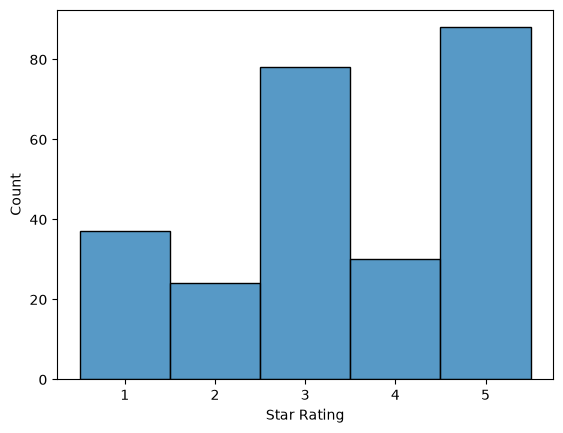

In [8]:
sns.histplot(df["Star Rating"], discrete=True);

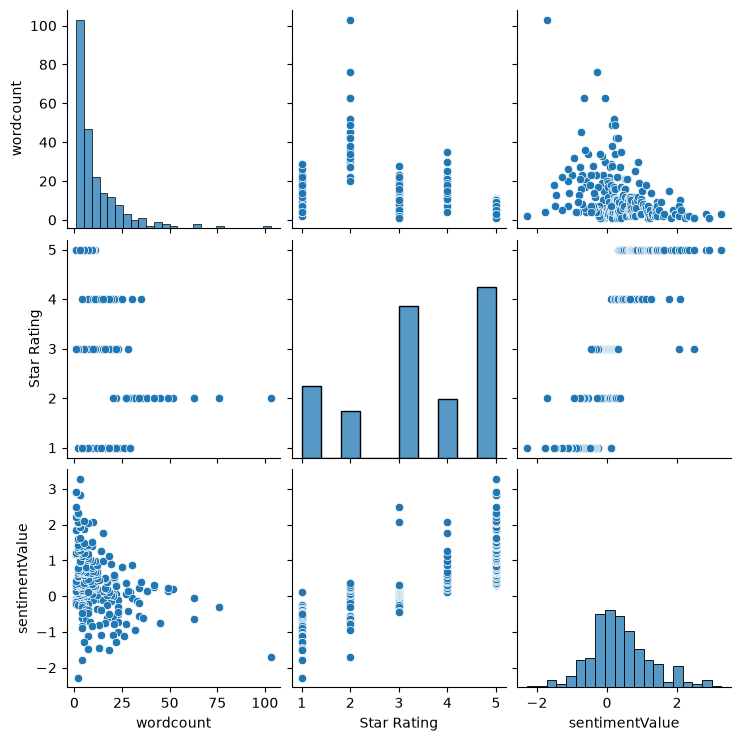

In [9]:
sns.pairplot(df);

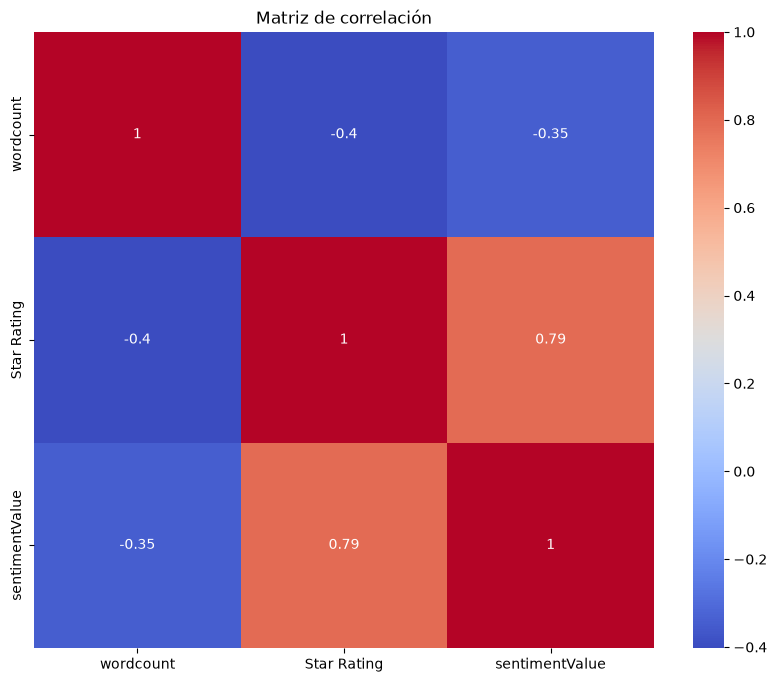

In [10]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only= True), annot=True, cmap="coolwarm")
plt.title("Matriz de correlación")
plt.show()

## Preparamos el dataset
Divide en train/test y escala las features en el rango [0, 1].

In [11]:
X = df[['wordcount', 'sentimentValue']]
y = df['Star Rating']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Creamos el Modelo
Entrena con un KNN y evalúa el error en train y en test

In [12]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_scaled, y_train)


y_train_pred = knn.predict(X_train_scaled)
y_test_pred = knn.predict(X_test_scaled)

In [13]:
print(knn.score(X_test_scaled, y_test))

0.9038461538461539


In [14]:
print(classification_report(y_train, y_train_pred))

              precision    recall  f1-score   support

           1       0.93      0.93      0.93        30
           2       0.85      0.89      0.87        19
           3       0.88      0.95      0.91        62
           4       0.88      0.62      0.73        24
           5       0.94      0.96      0.95        70

    accuracy                           0.91       205
   macro avg       0.90      0.87      0.88       205
weighted avg       0.91      0.91      0.90       205



In [15]:
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           1       1.00      1.00      1.00         7
           2       1.00      0.80      0.89         5
           3       0.83      0.94      0.88        16
           4       0.83      0.83      0.83         6
           5       0.94      0.89      0.91        18

    accuracy                           0.90        52
   macro avg       0.92      0.89      0.90        52
weighted avg       0.91      0.90      0.90        52



## Evalúa tu modelo

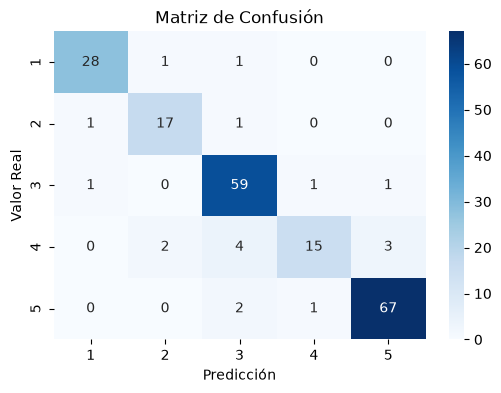

In [16]:
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_train, y_train_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=[1, 2, 3, 4, 5], yticklabels=[1, 2, 3, 4, 5])
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.title('Matriz de Confusión')
plt.show()

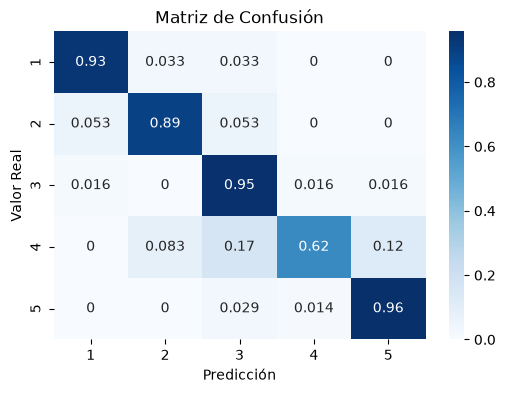

In [17]:
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_train, y_train_pred, normalize='true'), annot=True, cmap='Blues',
            xticklabels=[1, 2, 3, 4, 5], yticklabels=[1, 2, 3, 4, 5])
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.title('Matriz de Confusión')
plt.show()

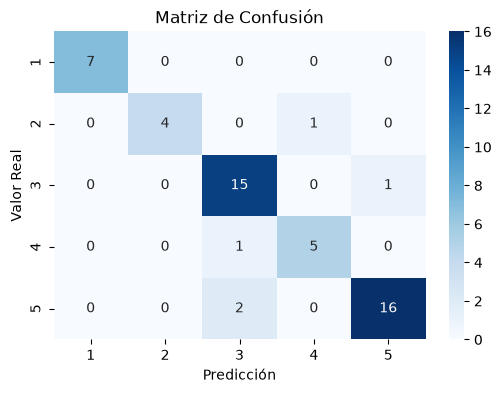

In [18]:
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_test_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=[1, 2, 3, 4, 5], yticklabels=[1, 2, 3, 4, 5])
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.title('Matriz de Confusión')
plt.show()

In [19]:
from sklearn import model_selection

kfold = model_selection.StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = ["accuracy", "precision_weighted", "f1_weighted"]

cv_results = model_selection.cross_validate(knn, X_train_scaled, y_train, cv=kfold, scoring=scoring)

for metrica in scoring:
  scores = cv_results[f"test_{metrica}"]
  print(f"{metrica}: {scores.mean():.4f} ({scores.std():.4f})")

accuracy: 0.8439 (0.0548)
precision_weighted: 0.8703 (0.0444)
f1_weighted: 0.8347 (0.0575)


## ¿Cómo obtener el mejor valor de k? Crea y evalúa nuevos modelos
¿Qué valor de k maximiza el accuracy? Representa todas las iteraciones en un scatterplot -> k vs accuracy

In [20]:
k_values = range(1, 21)
accuracies = []

for k in k_values:
    modelo = KNeighborsClassifier(n_neighbors=k)
    modelo.fit(X_train_scaled, y_train)
    pred = modelo.predict(X_test_scaled)
    accuracies.append(accuracy_score(y_test, pred))


mejor_k = k_values[np.argmax(accuracies)]
mejor_accuracy = max(accuracies)
print(f"El mejor valor de k es {mejor_k} con un accuracy de {mejor_accuracy:.4f}")

El mejor valor de k es 3 con un accuracy de 0.9038


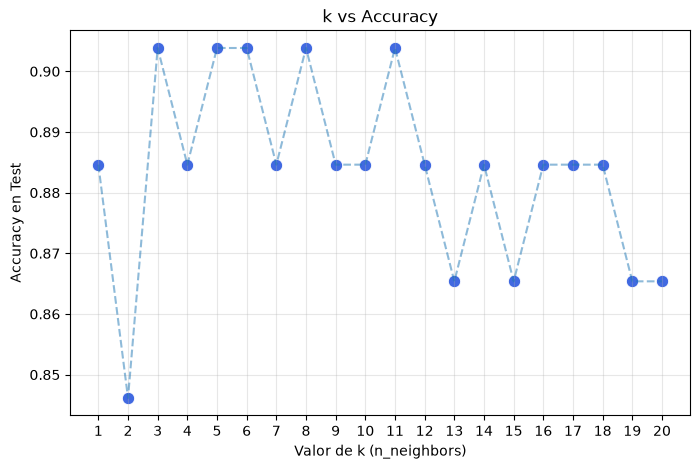

In [21]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x=list(k_values), y=accuracies, s=80, color='royalblue')
plt.plot(list(k_values), accuracies, linestyle='--', alpha=0.5)
plt.xticks(k_values)
plt.xlabel('Valor de k (n_neighbors)')
plt.ylabel('Accuracy en Test')
plt.title('k vs Accuracy')
plt.grid(True, alpha=0.3)
plt.show()

In [22]:
kfold = model_selection.StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

valores_k = range(1, 21)
resultados = {}

for k in valores_k:
    knn = KNeighborsClassifier(n_neighbors=k)

    scores = model_selection.cross_val_score(knn, X_train_scaled, y_train, cv=kfold, scoring="accuracy")
    resultados[k] = scores.mean()
    print(f"k={k:2d} -> accuracy media: {scores.mean():.4f} (+/- {scores.std():.4f})")

mejor_k = max(resultados, key=resultados.get)

k= 1 -> accuracy media: 0.8231 (+/- 0.0878)
k= 2 -> accuracy media: 0.8183 (+/- 0.0874)
k= 3 -> accuracy media: 0.8581 (+/- 0.0715)
k= 4 -> accuracy media: 0.8779 (+/- 0.0583)
k= 5 -> accuracy media: 0.8583 (+/- 0.0770)
k= 6 -> accuracy media: 0.8481 (+/- 0.0710)
k= 7 -> accuracy media: 0.8581 (+/- 0.0709)
k= 8 -> accuracy media: 0.8581 (+/- 0.0634)
k= 9 -> accuracy media: 0.8536 (+/- 0.0651)
k=10 -> accuracy media: 0.8536 (+/- 0.0569)
k=11 -> accuracy media: 0.8488 (+/- 0.0664)
k=12 -> accuracy media: 0.8536 (+/- 0.0651)
k=13 -> accuracy media: 0.8438 (+/- 0.0601)
k=14 -> accuracy media: 0.8388 (+/- 0.0615)
k=15 -> accuracy media: 0.8143 (+/- 0.0679)
k=16 -> accuracy media: 0.8140 (+/- 0.0650)
k=17 -> accuracy media: 0.8090 (+/- 0.0678)
k=18 -> accuracy media: 0.8240 (+/- 0.0659)
k=19 -> accuracy media: 0.8040 (+/- 0.0700)
k=20 -> accuracy media: 0.8140 (+/- 0.0687)


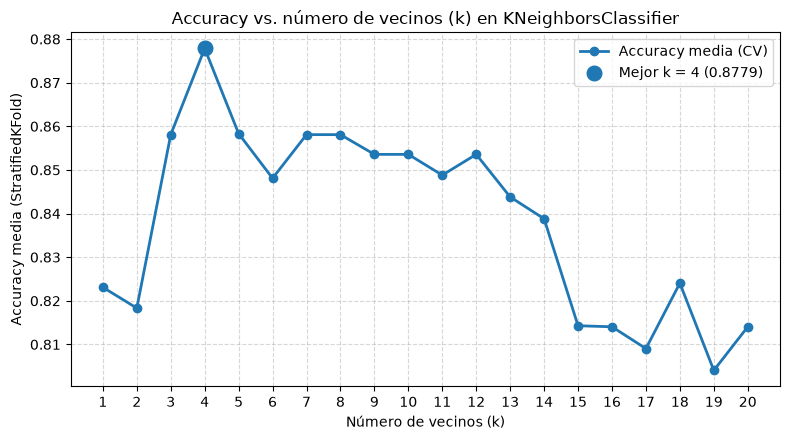

In [23]:
ks = list(resultados.keys())
accs = list(resultados.values())

plt.figure(figsize=(8, 4.5))
plt.plot(ks, accs, marker="o", linewidth=2, label="Accuracy media (CV)")


plt.scatter(
[mejor_k],
[resultados[mejor_k]],
s=110,
zorder=5,
label=f"Mejor k = {mejor_k} ({resultados[mejor_k]:.4f})",
)

plt.title("Accuracy vs. número de vecinos (k) en KNeighborsClassifier")
plt.xlabel("Número de vecinos (k)")
plt.ylabel("Accuracy media (StratifiedKFold)")
plt.xticks(ks)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

## Predice con nuevos datos.
Ejemplo: supongamos que nos llega una review de 5 palabras y sentimiento 1

In [24]:
modelo_top = KNeighborsClassifier(n_neighbors= mejor_k)
modelo_top.fit(X_train_scaled, y_train)

punto_nuevo = {'wordcount': [5],
               'sentimentValue': [1]}


punto_nuevo = pd.DataFrame(punto_nuevo)

nuevo_dato_scaled = scaler.transform(punto_nuevo)
prediccion = modelo_top.predict(nuevo_dato_scaled)

print(f"Para una review de 5 palabras y sentimiento 1, la predicción es: {prediccion[0]} estrellas")

Para una review de 5 palabras y sentimiento 1, la predicción es: 5 estrellas
